Faust Bsp.

In [23]:


# Import Spark Libraries
import findspark, os
findspark.init('/home/hadoop/spark')
from pyspark.sql import SparkSession

# Initialize Spark Session
spark = SparkSession.builder     .master("yarn")     .appName("Jupyter/PySpark Exercises")     .enableHiveSupport()     .config("spark.sql.hive.manageFilesourcePartitions", "false")     .getOrCreate()


In [24]:
# Read Input File
text_file = spark.read.text("/user/hadoop/Faust_1.txt").rdd.map(lambda r: r[0])

# Calculate Word Counts
words = text_file.flatMap(lambda line: line.split(" "))
counts = words.map(lambda word: (word, 1)).reduceByKey(lambda a,b:a +b)

# Collect result (to Spark Driver)
output = counts.collect()
sorted_output = sorted(output,key=lambda x:(-x[1],x[0]))

# Print Result
print(f'Word Count Output: {sorted_output[:10]}')

Word Count Output: [('', 1603), ('und', 509), ('die', 463), ('der', 440), ('ich', 435), ('Und', 400), ('nicht', 346), ('zu', 319), ('ist', 291), ('ein', 284)]


Filme

In [25]:
df_title_basics = (
    spark.read
    .format("csv")
    .options(
        header="true",
        delimiter="\t",
        nullValue=r"\N",
        inferSchema="true"
    )
    .load("/user/hadoop/imdb/title_basics/title.basics.tsv")
)

In [4]:
df_title_basics.printSchema()

root
 |-- tconst: string (nullable = true)
 |-- titleType: string (nullable = true)
 |-- primaryTitle: string (nullable = true)
 |-- originalTitle: string (nullable = true)
 |-- isAdult: integer (nullable = true)
 |-- startYear: integer (nullable = true)
 |-- endYear: integer (nullable = true)
 |-- runtimeMinutes: string (nullable = true)
 |-- genres: string (nullable = true)



In [5]:
df_title_basics.show(3)

+---------+---------+--------------------+--------------------+-------+---------+-------+--------------+--------------------+
|   tconst|titleType|        primaryTitle|       originalTitle|isAdult|startYear|endYear|runtimeMinutes|              genres|
+---------+---------+--------------------+--------------------+-------+---------+-------+--------------+--------------------+
|tt0000001|    short|          Carmencita|          Carmencita|      0|     1894|   null|             1|   Documentary,Short|
|tt0000002|    short|Le clown et ses c...|Le clown et ses c...|      0|     1892|   null|             5|     Animation,Short|
|tt0000003|    short|        Poor Pierrot|      Pauvre Pierrot|      0|     1892|   null|             5|Animation,Comedy,...|
+---------+---------+--------------------+--------------------+-------+---------+-------+--------------+--------------------+
only showing top 3 rows



In [6]:
df_title_basics.count()

12898691

In [7]:
from pyspark.sql.functions import desc
df_title_basics.groupBy("titleType").count().orderBy(desc("count")) .show()

+------------+-------+
|   titleType|  count|
+------------+-------+
|   tvEpisode|9978123|
|       short|1165535|
|       movie| 760577|
|       video| 332777|
|    tvSeries| 307622|
|     tvMovie| 156730|
|tvMiniSeries|  73875|
|   tvSpecial|  61590|
|   videoGame|  50778|
|     tvShort|  11083|
|     tvPilot|      1|
+------------+-------+



In [8]:
from pyspark.sql.functions import avg, col
(
df_title_basics
    .where(col('titleType') == 'movie')     
    .agg(avg('runtimeMinutes'))     
    .show()
)


+-------------------+
|avg(runtimeMinutes)|
+-------------------+
|  89.89716412873403|
+-------------------+



In [9]:
# Save Dataframe back to HDFS (partitioned) as Parquet files
(
df_title_basics.repartition('startYear')
    .write     
    .format("parquet")     
    .mode("overwrite")     
    .partitionBy('startYear')     
    .save('/user/hadoop/imdb/title_basics_partitioned_files')
    )

In [10]:
# Save Dataframe back to HDFS (partitioned) as EXTERNAL TABLE and Parquet files
(
df_title_basics.repartition('startYear').write     
.format("parquet")     
.mode("overwrite")     
.option('path', '/user/hadoop/imdb/title_basics_partitioned_table')     
.partitionBy('startYear')     
.saveAsTable('default.title_basics_partitioned')
)

In [11]:
spark.sql('SHOW TABLES').show(10, False)

+--------+------------------------+-----------+
|database|tableName               |isTemporary|
+--------+------------------------+-----------+
|default |title_basics_partitioned|false      |
+--------+------------------------+-----------+



In [12]:
# Read External Spark table programmatically
from pyspark.sql.functions import col

df = (
    spark.table('default.title_basics_partitioned')
    .where(col('startYear') == 2020)
    .select('tconst', 'primaryTitle', 'startYear')
)
df.show(3)


+---------+--------------------+---------+
|   tconst|        primaryTitle|startYear|
+---------+--------------------+---------+
|tt0060366|A Embalagem de Vidro|     2020|
|tt0062336|The Tango of the ...|     2020|
|tt0166938|               Yo-TV|     2020|
+---------+--------------------+---------+
only showing top 3 rows



In [13]:
# Read External Spark table using plain Spark SQL
df = spark.sql(
    'SELECT tconst, primaryTitle, startYear '
    'FROM default.title_basics_partitioned '
    'WHERE startYear = 2020'
)
df.show(3)


+---------+--------------------+---------+
|   tconst|        primaryTitle|startYear|
+---------+--------------------+---------+
|tt0060366|A Embalagem de Vidro|     2020|
|tt0062336|The Tango of the ...|     2020|
|tt0166938|               Yo-TV|     2020|
+---------+--------------------+---------+
only showing top 3 rows



In [14]:
# Read title.ratings.tsv into a Spark DataFrame
df_title_ratings = (
    spark.read
    .format('csv')
    .options(
        header='true',
        delimiter='\t',
        nullValue=r'\N',
        inferSchema='true'
    )
    .load('/user/hadoop/imdb/title_ratings/title.ratings.tsv')
)


In [15]:
df_title_ratings.printSchema()


root
 |-- tconst: string (nullable = true)
 |-- averageRating: double (nullable = true)
 |-- numVotes: integer (nullable = true)



In [16]:
df_title_ratings.show(3)


+---------+-------------+--------+
|   tconst|averageRating|numVotes|
+---------+-------------+--------+
|tt0000001|          5.7|    2238|
|tt0000002|          5.4|     327|
|tt0000003|          6.4|    2401|
+---------+-------------+--------+
only showing top 3 rows



In [17]:
# Join the DataFrames
joined_df = df_title_basics.join(
    df_title_ratings,
    df_title_basics.tconst == df_title_ratings.tconst
)


In [18]:
joined_df.printSchema()


root
 |-- tconst: string (nullable = true)
 |-- titleType: string (nullable = true)
 |-- primaryTitle: string (nullable = true)
 |-- originalTitle: string (nullable = true)
 |-- isAdult: integer (nullable = true)
 |-- startYear: integer (nullable = true)
 |-- endYear: integer (nullable = true)
 |-- runtimeMinutes: string (nullable = true)
 |-- genres: string (nullable = true)
 |-- tconst: string (nullable = true)
 |-- averageRating: double (nullable = true)
 |-- numVotes: integer (nullable = true)



In [19]:
joined_df.show(3)


+---------+---------+--------------------+--------------------+-------+---------+-------+--------------+---------------+---------+-------------+--------+
|   tconst|titleType|        primaryTitle|       originalTitle|isAdult|startYear|endYear|runtimeMinutes|         genres|   tconst|averageRating|numVotes|
+---------+---------+--------------------+--------------------+-------+---------+-------+--------------+---------------+---------+-------------+--------+
|tt0000658|    short|The Puppet's Nigh...|Le cauchemar de F...|      0|     1908|   null|             2|Animation,Short|tt0000658|          6.4|     352|
|tt0001732|    short|The Lighthouse Ke...|The Lighthouse Ke...|      0|     1911|   null|            10|    Drama,Short|tt0001732|          5.7|      43|
|tt0002253|    short|          Home Folks|          Home Folks|      0|     1912|   null|            17|    Drama,Short|tt0002253|          5.3|      40|
+---------+---------+--------------------+--------------------+-------+-----

In [20]:
from pyspark.sql.functions import col, desc

top_tvseries = (
    joined_df
    .where(col('titleType') == 'tvSeries')
    .where(col('numVotes') > 200000)
    .orderBy(desc('averageRating'))
    .select(
        'originalTitle', 'startYear', 'endYear',
        'averageRating', 'numVotes'
    )
)
top_tvseries.show(5)


+--------------------+---------+-------+-------------+--------+
|       originalTitle|startYear|endYear|averageRating|numVotes|
+--------------------+---------+-------+-------------+--------+
|        Breaking Bad|     2008|   2013|          9.5| 2697144|
|Avatar: The Last ...|     2005|   2008|          9.3|  459535|
|            The Wire|     2002|   2008|          9.3|  443022|
|     Game of Thrones|     2011|   2019|          9.2| 2678332|
|        The Sopranos|     1999|   2007|          9.2|  603748|
+--------------------+---------+-------+-------------+--------+
only showing top 5 rows



In [21]:
from pyspark.sql.functions import when, lit

df_with_classification = (
    joined_df
    .withColumn(
        'classification',
        when(col('averageRating') > 8, lit('good'))
        .otherwise(lit('worse'))
    )
    .select(
        'primaryTitle', 'startYear',
        'averageRating', 'classification'
    )
)
df_with_classification.show(3, False)


+----------------------+---------+-------------+--------------+
|primaryTitle          |startYear|averageRating|classification|
+----------------------+---------+-------------+--------------+
|The Puppet's Nightmare|1908     |6.4          |worse         |
|The Lighthouse Keeper |1911     |5.7          |worse         |
|Home Folks            |1912     |5.3          |worse         |
+----------------------+---------+-------------+--------------+
only showing top 3 rows



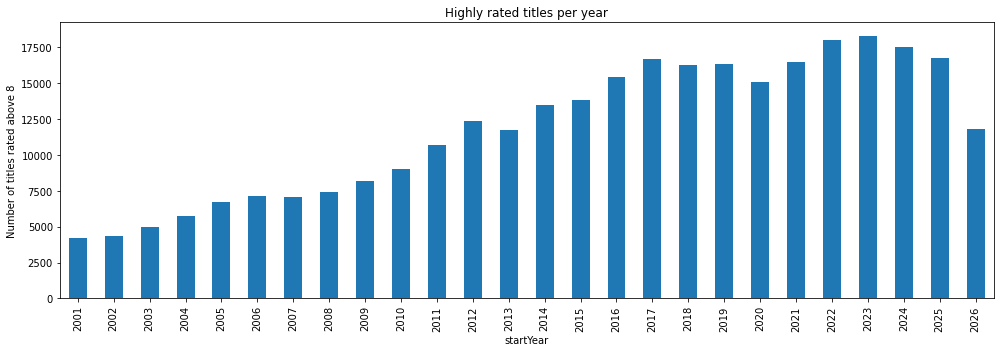

In [22]:
import matplotlib.pyplot as plt

# Same scope as Exercises.py: all title types, not only movies.
good_movies = (
    df_with_classification
    .select('startYear', 'classification')
    .where(col('classification') == 'good')
    .where(col('startYear') > 2000)
    .groupBy('startYear')
    .count()
    .sort(col('startYear').asc())
)

pandas_df = good_movies.toPandas()
pandas_df.plot.bar(
    x='startYear',
    y='count',
    figsize=(14, 5),
    legend=False
)
plt.ylabel('Number of titles rated above 8')
plt.title('Highly rated titles per year')
plt.tight_layout()
plt.show()


Aufgabe

In [29]:
df_name_basics = (
    spark.read
    .format("csv")
    .options(
        header="true",
        delimiter="\t",
        nullValue=r"\N",
        inferSchema="true"
    )
    .load("/user/hadoop/imdb/name_basics/name.basics.tsv")
)

In [30]:
df_name_basics.printSchema()

root
 |-- nconst: string (nullable = true)
 |-- primaryName: string (nullable = true)
 |-- birthYear: integer (nullable = true)
 |-- deathYear: integer (nullable = true)
 |-- primaryProfession: string (nullable = true)
 |-- knownForTitles: string (nullable = true)



In [32]:
from pyspark.sql.functions import col, desc

(
    df_title_basics
    .where(col("titleType").isin("movie", "tvSeries"))
    .groupBy("titleType")
    .count()
    .orderBy(desc("count"))
    .show()
)

+---------+------+
|titleType| count|
+---------+------+
|    movie|760577|
| tvSeries|307622|
+---------+------+

